# Notebook 2 V4 — Species Training + Bucket Evaluation

**Final design**: Train a 179-class species classifier on frozen CLIP embeddings, evaluate at both species level (direct comparison with Picek 2022 benchmark) AND bucket level (edibility aggregation for real-world interpretability).

## Why this design

- **Species supervision** is richer than bucket supervision (179-way signal vs 4-way)
- Picek 2022 benchmark is species-level → direct numerical comparison possible
- **Bucket evaluation** captures the real-world "is it edible?" decision
- Many species-level errors collapse in bucket aggregation (same-genus confusion → same bucket), so bucket accuracy often remains high even when species accuracy is mediocre

## Key changes from V3

| | V3 (bucket training) | V4 (species training) |
|---|---|---|
| Training target | 4-class bucket | **179-class species** |
| AL strategy operates on | 4-class probabilities | **179-class probabilities** (richer uncertainty signal) |
| N_INIT | 400 | **1800** (~10 per species) |
| MAX_LABELS | 3000 (9%) | **10000 (31%)** |
| BATCH_SIZE | 100 | **200** |
| Evaluation | 4-class only | **Both species AND bucket** |

## Research questions

1. Does species training → bucket aggregation outperform direct bucket training?
2. Does the AL strategy ranking change when uncertainty is measured at the fine-grained (species) level?
3. What's the bucket-accuracy cost of reducing from 100% → 31% labels under each strategy?


In [1]:
# ==================== IMPORTS ====================
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import accuracy_score, f1_score, recall_score

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

if torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.cuda.is_available():
    DEVICE = torch.device('cuda')
else:
    DEVICE = torch.device('cpu')
print(f"Device: {DEVICE}")

Device: mps


In [2]:
# ==================== CONFIG ====================
ARTIFACTS_DIR = Path('artifacts')
RESULTS_DIR   = Path('results')
RESULTS_DIR.mkdir(exist_ok=True, parents=True)

# Bucket (evaluation only, not training)
BUCKET_ORDER = ['SAFE', 'COOK_FIRST', 'AVOID', 'UNCERTAIN']
N_BUCKETS    = len(BUCKET_ORDER)

# AL config — EXPANDED BUDGET vs V3
N_INIT         = 1800         # ~10 per species (vs 400 before)
BATCH_SIZE_AL  = 200          # per round (vs 100)
MAX_LABELS     = 10000        # 31% of pool (vs 9% in V3)
N_SEEDS        = 5

# MLP config
HIDDEN_DIMS    = (512, 256)   # larger hidden — 179 classes needs more capacity
DROPOUT_P      = 0.2
MLP_EPOCHS     = 30           # reduced from 40; with more data less epochs needed
MLP_LR         = 1e-3
MLP_WD         = 1e-4
MLP_BATCH      = 128          # larger batch for speed
MC_SAMPLES     = 20

## Step 1 — Load Data (Species Labels for Training, Bucket Labels for Evaluation)

In [6]:
embeddings = np.load(ARTIFACTS_DIR / 'df20m_embeddings.npy').astype(np.float32)
metadata   = pd.read_csv(ARTIFACTS_DIR / 'df20m_metadata.csv')
species_info = pd.read_csv(ARTIFACTS_DIR / 'species_info.csv')
buckets_df = pd.read_csv(ARTIFACTS_DIR / 'species_edibility_with_buckets.csv')

metadata['species_id']    = metadata['species_id'].astype(int)
metadata['embedding_idx'] = metadata['embedding_idx'].astype(int)

# species_id → bucket_idx mapping array for evaluation
bucket_to_idx = {b: i for i, b in enumerate(BUCKET_ORDER)}
species_name_to_bucket_idx = {
    row['species']: bucket_to_idx[row['bucket']]
    for _, row in buckets_df.iterrows()
}
id_to_species_name = dict(zip(species_info['species_id'], species_info['species']))

N_SPECIES = int(metadata['species_id'].max()) + 1

# FIX: single-level dict lookup (was nested before, causing all species → UNCERTAIN)
species_id_to_bucket_idx = np.array([
    species_name_to_bucket_idx.get(
        id_to_species_name[sid],
        bucket_to_idx['UNCERTAIN']
    )
    for sid in range(N_SPECIES)
])

# Sanity check — MUST show 21/37/96/25, NOT 0/0/0/179
print(f"species_name_to_bucket_idx has {len(species_name_to_bucket_idx)} entries")
print(f"Sample: {dict(list(species_name_to_bucket_idx.items())[:3])}")
print(f"species_id_to_bucket_idx distribution (179 species total):")
for i, b in enumerate(BUCKET_ORDER):
    n = (species_id_to_bucket_idx == i).sum()
    print(f"  {b:12s} {n:3d} species")

# Build pool/test splits
train_mask = metadata['split'].values == 'train'
test_mask  = metadata['split'].values == 'test'

X_pool = embeddings[train_mask]
y_pool_species = metadata.loc[train_mask, 'species_id'].to_numpy()
X_test = embeddings[test_mask]
y_test_species = metadata.loc[test_mask, 'species_id'].to_numpy()
y_test_bucket  = species_id_to_bucket_idx[y_test_species]

test_genus_arr = metadata.loc[test_mask, 'genus'].to_numpy()

EMBED_DIM = X_pool.shape[1]
print(f"\nPool:  {X_pool.shape[0]:,} × {EMBED_DIM}")
print(f"Test:  {X_test.shape[0]:,}")
print(f"Species classes:   {N_SPECIES}")
print(f"Bucket classes:    {N_BUCKETS}  ({BUCKET_ORDER})")
print(f"\nTest bucket distribution (for reference):")
for i, b in enumerate(BUCKET_ORDER):
    n = (y_test_bucket == i).sum()
    print(f"  {b:12s} {n:5d} ({100*n/len(y_test_bucket):.1f}%)")

species_name_to_bucket_idx has 179 entries
Sample: {'Agaricus arvensis': 0, 'Agaricus augustus': 0, 'Agaricus bernardii': 1}
species_id_to_bucket_idx distribution (179 species total):
  SAFE          21 species
  COOK_FIRST    37 species
  AVOID         96 species
  UNCERTAIN     25 species

Pool:  32,724 × 512
Test:  3,637
Species classes:   179
Bucket classes:    4  (['SAFE', 'COOK_FIRST', 'AVOID', 'UNCERTAIN'])

Test bucket distribution (for reference):
  SAFE           546 (15.0%)
  COOK_FIRST     764 (21.0%)
  AVOID         2073 (57.0%)
  UNCERTAIN      254 (7.0%)


## Step 2 — MLP with MC Dropout (179-class output)

In [7]:
class MCDropoutMLP(nn.Module):
    def __init__(self, input_dim, hidden_dims, n_classes, dropout_p=0.2):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers.append(nn.Linear(prev, h))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout_p))
            prev = h
        layers.append(nn.Linear(prev, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def train_mlp(X, y, n_classes, device=DEVICE, epochs=MLP_EPOCHS,
              lr=MLP_LR, weight_decay=MLP_WD, batch=MLP_BATCH):
    model = MCDropoutMLP(X.shape[1], HIDDEN_DIMS, n_classes, DROPOUT_P).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    crit = nn.CrossEntropyLoss()

    X_t = torch.from_numpy(X).float().to(device)
    y_t = torch.from_numpy(y).long().to(device)
    loader = DataLoader(TensorDataset(X_t, y_t), batch_size=batch, shuffle=True)

    model.train()
    for ep in range(epochs):
        for xb, yb in loader:
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            opt.step()
    return model


@torch.no_grad()
def predict_proba_single(model, X, device=DEVICE, batch=1024):
    model.eval()
    X_t = torch.from_numpy(X).float()
    probs = []
    for i in range(0, len(X_t), batch):
        xb = X_t[i:i+batch].to(device)
        p = F.softmax(model(xb), dim=1)
        probs.append(p.cpu().numpy())
    return np.concatenate(probs, axis=0)


@torch.no_grad()
def predict_proba_mc(model, X, T=MC_SAMPLES, device=DEVICE, batch=1024):
    model.train()
    X_t = torch.from_numpy(X).float()
    all_probs = []
    for t in range(T):
        probs_t = []
        for i in range(0, len(X_t), batch):
            xb = X_t[i:i+batch].to(device)
            p = F.softmax(model(xb), dim=1)
            probs_t.append(p.cpu().numpy())
        all_probs.append(np.concatenate(probs_t, axis=0))
    return np.stack(all_probs, axis=0)


def predict_species(model, X, device=DEVICE):
    p = predict_proba_single(model, X, device)
    return p.argmax(axis=1)

## Step 3 — Full-Supervision Ceiling

**This is the most important baseline experiment.** Train on ALL species labels, evaluate both species and bucket metrics. If bucket accuracy > 80% here, the species-training approach is validated. If species accuracy > 40%, we're operating in a useful regime for AL comparison.

In [9]:
t0 = time.time()
full_model = train_mlp(X_pool, y_pool_species, N_SPECIES, epochs=MLP_EPOCHS)
print(f"Full-sup training: {time.time()-t0:.1f}s")

# Species-level evaluation
y_pred_species = predict_species(full_model, X_test)
full_species_acc = accuracy_score(y_test_species, y_pred_species)
full_species_f1  = f1_score(y_test_species, y_pred_species, average='macro', zero_division=0)

# HARD aggregation (argmax species → bucket lookup)
y_pred_bucket_hard = species_id_to_bucket_idx[y_pred_species]
full_bucket_acc_hard = accuracy_score(y_test_bucket, y_pred_bucket_hard)
full_bucket_f1_hard  = f1_score(y_test_bucket, y_pred_bucket_hard, average='macro', zero_division=0)
full_bucket_recalls_hard = recall_score(
    y_test_bucket, y_pred_bucket_hard, average=None, zero_division=0,
    labels=list(range(N_BUCKETS)),
)

# SOFT aggregation (sum species probs within each bucket)
p_species_test = predict_proba_single(full_model, X_test)
p_bucket_test = np.zeros((len(p_species_test), N_BUCKETS), dtype=np.float32)
for bi in range(N_BUCKETS):
    mask = species_id_to_bucket_idx == bi
    p_bucket_test[:, bi] = p_species_test[:, mask].sum(axis=1)
y_pred_bucket_soft = p_bucket_test.argmax(axis=1)
full_bucket_acc_soft = accuracy_score(y_test_bucket, y_pred_bucket_soft)
full_bucket_f1_soft  = f1_score(y_test_bucket, y_pred_bucket_soft, average='macro', zero_division=0)
full_bucket_recalls_soft = recall_score(
    y_test_bucket, y_pred_bucket_soft, average=None, zero_division=0,
    labels=list(range(N_BUCKETS)),
)

# Backward-compat aliases (used by plotting cells later)
full_bucket_acc      = full_bucket_acc_hard
full_bucket_f1       = full_bucket_f1_hard
full_bucket_recalls  = full_bucket_recalls_hard

print(f"\n=== Full-supervision ({len(X_pool):,} labels) ===")
print(f"\nSPECIES level (179-way):")
print(f"  Top-1 accuracy: {full_species_acc:.3f}   (compare Picek ViT-L/16: 0.758)")
print(f"  Macro F1:       {full_species_f1:.3f}   (compare Picek ViT-L/16: 0.743)")

print(f"\nBUCKET level — HARD aggregation (argmax then lookup):")
print(f"  Accuracy:       {full_bucket_acc_hard:.3f}")
print(f"  Macro F1:       {full_bucket_f1_hard:.3f}")
print(f"  Per-bucket recall:")
for i, b in enumerate(BUCKET_ORDER):
    print(f"    {b:12s} {full_bucket_recalls_hard[i]:.3f}")

print(f"\nBUCKET level — SOFT aggregation (Σ species probs per bucket):")
print(f"  Accuracy:       {full_bucket_acc_soft:.3f}   ({full_bucket_acc_soft-full_bucket_acc_hard:+.3f} vs hard)")
print(f"  Macro F1:       {full_bucket_f1_soft:.3f}   ({full_bucket_f1_soft-full_bucket_f1_hard:+.3f} vs hard)")
print(f"  Per-bucket recall:")
for i, b in enumerate(BUCKET_ORDER):
    delta = full_bucket_recalls_soft[i] - full_bucket_recalls_hard[i]
    print(f"    {b:12s} {full_bucket_recalls_soft[i]:.3f}  ({delta:+.3f})")

majority_class = int(np.argmax(np.bincount(y_test_bucket)))
majority_acc = (y_test_bucket == majority_class).mean()
print(f"\nBucket majority baseline: {majority_acc:.3f}")

Full-sup training: 12.3s

=== Full-supervision (32,724 labels) ===

SPECIES level (179-way):
  Top-1 accuracy: 0.458   (compare Picek ViT-L/16: 0.758)
  Macro F1:       0.319   (compare Picek ViT-L/16: 0.743)

BUCKET level — HARD aggregation (argmax then lookup):
  Accuracy:       0.748
  Macro F1:       0.638
  Per-bucket recall:
    SAFE         0.661
    COOK_FIRST   0.645
    AVOID        0.857
    UNCERTAIN    0.354

BUCKET level — SOFT aggregation (Σ species probs per bucket):
  Accuracy:       0.764   (+0.016 vs hard)
  Macro F1:       0.646   (+0.008 vs hard)
  Per-bucket recall:
    SAFE         0.663  (+0.002)
    COOK_FIRST   0.662  (+0.017)
    AVOID        0.885  (+0.028)
    UNCERTAIN    0.295  (-0.059)

Bucket majority baseline: 0.570


## Step 4 — Evaluation Function (Both Levels)

In [12]:
def evaluate(model, X_test, y_test_species, y_test_bucket, test_genus_arr,
             species_id_to_bucket_idx, classes_seen):
    """Evaluate species; report species + bucket (both hard & soft aggregation)."""
    # Full probability distribution (N, 179)
    p_species = predict_proba_single(model, X_test)
    y_pred_species = p_species.argmax(axis=1)

    # Species-level metrics
    sp_acc = accuracy_score(y_test_species, y_pred_species)
    sp_f1  = f1_score(y_test_species, y_pred_species, average='macro', zero_division=0)

    # HARD aggregation
    y_pred_bucket_hard = species_id_to_bucket_idx[y_pred_species]
    bk_acc_hard = accuracy_score(y_test_bucket, y_pred_bucket_hard)
    bk_f1_hard  = f1_score(y_test_bucket, y_pred_bucket_hard, average='macro', zero_division=0)
    bucket_recalls_hard = recall_score(
        y_test_bucket, y_pred_bucket_hard, average=None, zero_division=0,
        labels=list(range(N_BUCKETS)),
    )

    # SOFT aggregation (Bayes-optimal)
    p_bucket = np.zeros((len(p_species), N_BUCKETS), dtype=np.float32)
    for bi in range(N_BUCKETS):
        mask = species_id_to_bucket_idx == bi
        p_bucket[:, bi] = p_species[:, mask].sum(axis=1)
    y_pred_bucket_soft = p_bucket.argmax(axis=1)
    bk_acc_soft = accuracy_score(y_test_bucket, y_pred_bucket_soft)
    bk_f1_soft  = f1_score(y_test_bucket, y_pred_bucket_soft, average='macro', zero_division=0)
    bucket_recalls_soft = recall_score(
        y_test_bucket, y_pred_bucket_soft, average=None, zero_division=0,
        labels=list(range(N_BUCKETS)),
    )

    # Assemble per-bucket recall keys for both methods
    bucket_metrics = {}
    for i in range(N_BUCKETS):
        bucket_metrics[f'recall_{BUCKET_ORDER[i]}']      = bucket_recalls_hard[i]
        bucket_metrics[f'recall_{BUCKET_ORDER[i]}_soft'] = bucket_recalls_soft[i]

    # Per-genus species accuracy
    per_genus = {}
    for g in np.unique(test_genus_arr):
        m = test_genus_arr == g
        per_genus[f'acc_{g}'] = accuracy_score(y_test_species[m], y_pred_species[m])

    return {
        'species_acc':      sp_acc,
        'species_f1':       sp_f1,
        'bucket_acc':       bk_acc_hard,    # default "bucket_acc" = hard
        'bucket_f1':        bk_f1_hard,
        'bucket_acc_soft':  bk_acc_soft,
        'bucket_f1_soft':   bk_f1_soft,
        'n_classes_seen':   len(classes_seen),
        **bucket_metrics,
        **per_genus,
    }

## Step 5 — Query Strategies (Operating on 179-class Probabilities)

The strategies are structurally identical to V3 but now see 179-dim probability distributions. This means:
- **Entropy** has much wider range (log2(179) ≈ 7.5 bits vs log2(4) = 2 bits)
- **Margin** can detect much finer distinctions (e.g. Amanita muscaria vs A. pantherina)
- **BALD** has more meaningful epistemic uncertainty signal per sample

In [13]:
def query_random(X_labeled, y_labeled, X_unlabeled, model, batch_size, rng):
    return rng.choice(len(X_unlabeled), size=batch_size, replace=False)


def query_entropy(X_labeled, y_labeled, X_unlabeled, model, batch_size, rng):
    p = predict_proba_single(model, X_unlabeled)
    entropy = -np.sum(p * np.log(p + 1e-12), axis=1)
    return np.argsort(entropy)[-batch_size:]


def query_margin(X_labeled, y_labeled, X_unlabeled, model, batch_size, rng):
    p = predict_proba_single(model, X_unlabeled)
    p_sorted = np.sort(p, axis=1)
    margin = p_sorted[:, -1] - p_sorted[:, -2]
    return np.argsort(margin)[:batch_size]


def query_coreset(X_labeled, y_labeled, X_unlabeled, model, batch_size, rng):
    sim_to_labeled = X_unlabeled @ X_labeled.T
    min_dist = 1.0 - sim_to_labeled.max(axis=1)
    picked = []
    for _ in range(batch_size):
        idx = int(np.argmax(min_dist))
        picked.append(idx)
        new_sim = X_unlabeled @ X_unlabeled[idx]
        min_dist = np.minimum(min_dist, 1.0 - new_sim)
        min_dist[idx] = -np.inf
    return np.array(picked)


def make_class_balanced_entropy(train_class_freq):
    weights = 1.0 / np.sqrt(train_class_freq + 1)
    weights = weights / weights.sum()
    def _strategy(X_labeled, y_labeled, X_unlabeled, model, batch_size, rng):
        p = predict_proba_single(model, X_unlabeled)
        entropy = -np.sum(p * np.log(p + 1e-12), axis=1)
        pred_class = p.argmax(axis=1)
        tail_weight = weights[pred_class]
        score = entropy * tail_weight
        return np.argsort(score)[-batch_size:]
    return _strategy


def query_bald(X_labeled, y_labeled, X_unlabeled, model, batch_size, rng):
    probs = predict_proba_mc(model, X_unlabeled, T=MC_SAMPLES)
    mean_p = probs.mean(axis=0)
    pred_entropy = -np.sum(mean_p * np.log(mean_p + 1e-12), axis=1)
    per_sample_entropy = -np.sum(probs * np.log(probs + 1e-12), axis=2).mean(axis=0)
    bald_score = pred_entropy - per_sample_entropy
    return np.argsort(bald_score)[-batch_size:]

## Step 6 — Stratified Init (per Species)

With 179 classes and 1800 init labels, we aim for 10 samples per species on average. Classes with <10 samples use all available; extras fill remaining budget.

In [14]:
def stratified_init(X_pool, y_pool, n_init, n_classes, rng, max_per_class=None):
    target_per_class = max(n_init // n_classes, 1)
    if max_per_class is not None:
        target_per_class = min(target_per_class, max_per_class)
    picked = []
    for c in range(n_classes):
        class_idx = np.where(y_pool == c)[0]
        if len(class_idx) == 0:
            continue
        take = min(target_per_class, len(class_idx))
        picked.extend(rng.choice(class_idx, size=take, replace=False).tolist())
    picked = np.array(picked)
    if len(picked) < n_init:
        remaining = np.setdiff1d(np.arange(len(X_pool)), picked)
        extra_n = min(n_init - len(picked), len(remaining))
        extra = rng.choice(remaining, size=extra_n, replace=False)
        picked = np.concatenate([picked, extra])
    return picked[:n_init]

## Step 7 — AL Trajectory

In [15]:
def run_al_trajectory(
    X_pool, y_pool_species,
    X_test, y_test_species, y_test_bucket, test_genus_arr,
    species_id_to_bucket_idx,
    strategy_name, strategy_fn,
    n_init, batch_size, max_labels,
    seed, n_classes,
):
    rng = np.random.RandomState(seed)
    torch.manual_seed(seed)

    init_idx = stratified_init(X_pool, y_pool_species, n_init, n_classes, rng)
    labeled_mask = np.zeros(len(X_pool), dtype=bool)
    labeled_mask[init_idx] = True

    history = []
    while labeled_mask.sum() <= max_labels:
        X_labeled = X_pool[labeled_mask]
        y_labeled = y_pool_species[labeled_mask]
        classes_seen = np.unique(y_labeled)

        model = train_mlp(X_labeled, y_labeled, n_classes)
        metrics = evaluate(
            model, X_test, y_test_species, y_test_bucket, test_genus_arr,
            species_id_to_bucket_idx, classes_seen,
        )
        metrics['n_labels']  = int(labeled_mask.sum())
        metrics['strategy']  = strategy_name
        metrics['seed']      = seed
        history.append(metrics)

        if labeled_mask.sum() >= max_labels:
            break

        unlabeled_mask = ~labeled_mask
        unlabeled_idx  = np.where(unlabeled_mask)[0]
        X_unlabeled    = X_pool[unlabeled_idx]

        local_picks = strategy_fn(
            X_labeled, y_labeled, X_unlabeled, model,
            batch_size=batch_size, rng=rng,
        )
        global_picks = unlabeled_idx[local_picks]
        labeled_mask[global_picks] = True

    return pd.DataFrame(history)

## Step 8 — Experiment Matrix

6 strategies × 5 seeds. With 10k max labels and 200 batch, each trajectory has ~41 rounds.

Expected runtime: **90-180 minutes** on M4 MPS (BALD is slowest due to MC sampling).

In [16]:
train_class_freq = np.bincount(y_pool_species, minlength=N_SPECIES)
cb_entropy = make_class_balanced_entropy(train_class_freq)

STRATEGIES = {
    'random':     query_random,
    'entropy':    query_entropy,
    'margin':     query_margin,
    'coreset':    query_coreset,
    'cb_entropy': cb_entropy,
    'bald':       query_bald,
}
SEEDS = list(range(N_SEEDS))

print(f"Strategies: {list(STRATEGIES.keys())}")
print(f"Seeds:      {SEEDS}")
print(f"Total runs: {len(STRATEGIES) * len(SEEDS)}")
print(f"\nBudget: {N_INIT} init → {MAX_LABELS} max, batch={BATCH_SIZE_AL}")
print(f"Rounds per trajectory: {(MAX_LABELS - N_INIT)//BATCH_SIZE_AL + 1}")

Strategies: ['random', 'entropy', 'margin', 'coreset', 'cb_entropy', 'bald']
Seeds:      [0, 1, 2, 3, 4]
Total runs: 30

Budget: 1800 init → 10000 max, batch=200
Rounds per trajectory: 42


In [17]:
all_histories = []
log_path = RESULTS_DIR / 'learning_curves_v4.csv'

t_start = time.time()
for strategy_name, strategy_fn in STRATEGIES.items():
    for seed in SEEDS:
        t0 = time.time()
        df = run_al_trajectory(
            X_pool, y_pool_species,
            X_test, y_test_species, y_test_bucket, test_genus_arr,
            species_id_to_bucket_idx,
            strategy_name, strategy_fn,
            n_init=N_INIT, batch_size=BATCH_SIZE_AL, max_labels=MAX_LABELS,
            seed=seed, n_classes=N_SPECIES,
        )
        elapsed = time.time() - t0
        final = df.iloc[-1]
        print(f"[{strategy_name:12s} seed={seed}] "
              f"sp_acc={final['species_acc']:.3f}  "
              f"bk_acc={final['bucket_acc']:.3f}  "
              f"bk_f1={final['bucket_f1']:.3f}  "
              f"UNC={final['recall_UNCERTAIN']:.3f}  "
              f"({elapsed:.0f}s, {len(df)} rds)")
        all_histories.append(df)
        pd.concat(all_histories, ignore_index=True).to_csv(log_path, index=False)

print(f"\nTotal elapsed: {(time.time() - t_start)/60:.1f} minutes")
print(f"Saved: {log_path}")

[random       seed=0] sp_acc=0.380  bk_acc=0.693  bk_f1=0.571  UNC=0.335  (86s, 42 rds)
[random       seed=1] sp_acc=0.374  bk_acc=0.690  bk_f1=0.580  UNC=0.417  (86s, 42 rds)
[random       seed=2] sp_acc=0.371  bk_acc=0.700  bk_f1=0.579  UNC=0.315  (75s, 42 rds)
[random       seed=3] sp_acc=0.380  bk_acc=0.697  bk_f1=0.580  UNC=0.378  (74s, 42 rds)
[random       seed=4] sp_acc=0.370  bk_acc=0.699  bk_f1=0.579  UNC=0.335  (74s, 42 rds)
[entropy      seed=0] sp_acc=0.361  bk_acc=0.706  bk_f1=0.592  UNC=0.382  (76s, 42 rds)
[entropy      seed=1] sp_acc=0.359  bk_acc=0.707  bk_f1=0.580  UNC=0.311  (76s, 42 rds)
[entropy      seed=2] sp_acc=0.356  bk_acc=0.708  bk_f1=0.591  UNC=0.358  (76s, 42 rds)
[entropy      seed=3] sp_acc=0.352  bk_acc=0.703  bk_f1=0.578  UNC=0.315  (75s, 42 rds)
[entropy      seed=4] sp_acc=0.358  bk_acc=0.702  bk_f1=0.580  UNC=0.350  (74s, 42 rds)
[margin       seed=0] sp_acc=0.377  bk_acc=0.712  bk_f1=0.596  UNC=0.366  (73s, 42 rds)
[margin       seed=1] sp_acc=0.3

## Step 9 — Learning Curves

4 panels: species accuracy, species F1, bucket accuracy, bucket F1. All show the full-sup ceilings for reference.

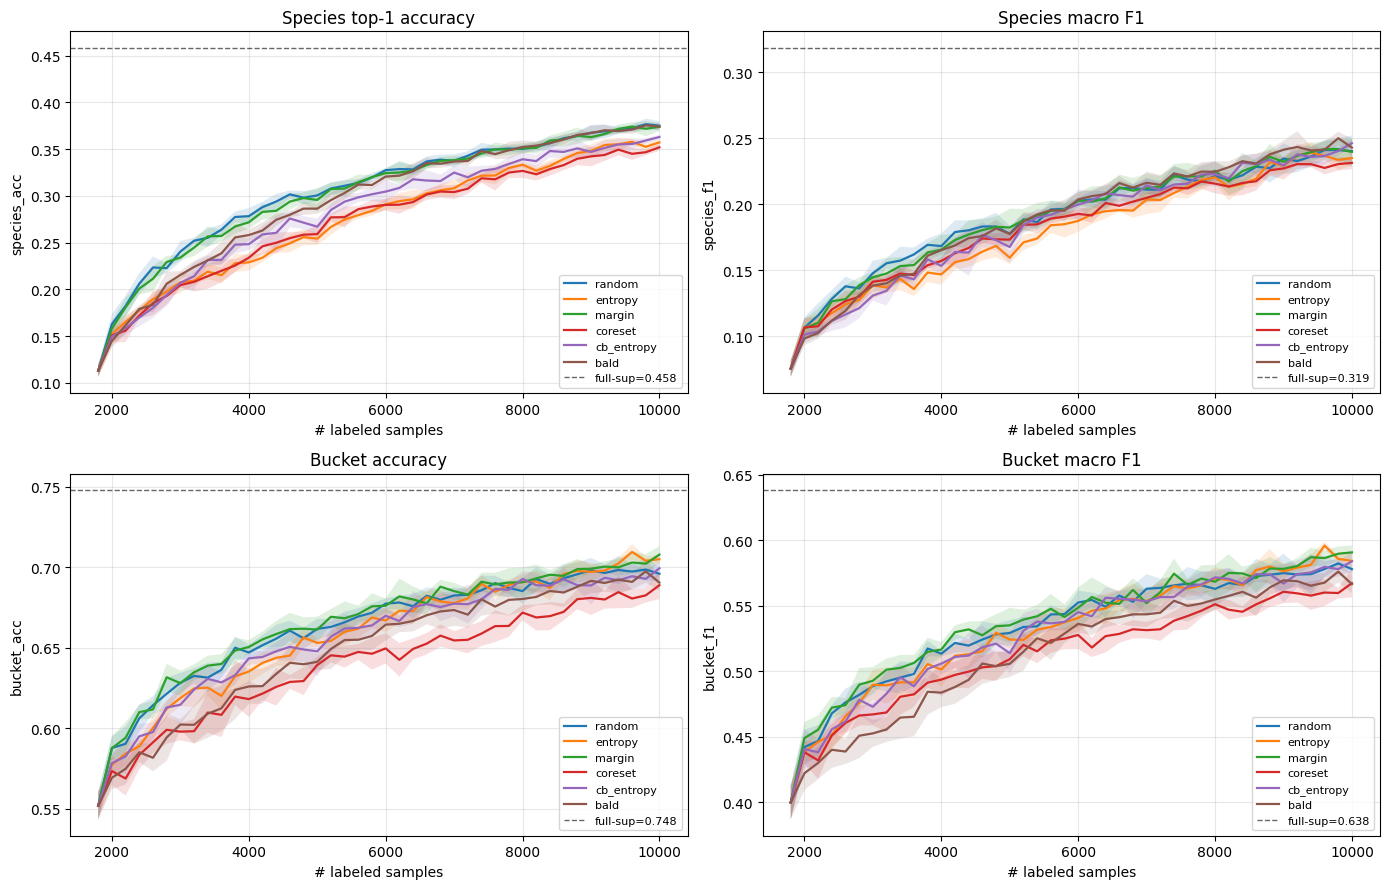

In [18]:
results = pd.concat(all_histories, ignore_index=True)

def plot_curve(results, metric, ax, title, ceiling=None):
    for strategy in STRATEGIES:
        sub = results[results['strategy'] == strategy]
        agg = sub.groupby('n_labels')[metric].agg(['mean', 'std']).reset_index()
        ax.plot(agg['n_labels'], agg['mean'], label=strategy, linewidth=1.6)
        ax.fill_between(agg['n_labels'],
                        agg['mean'] - agg['std'],
                        agg['mean'] + agg['std'],
                        alpha=0.15)
    if ceiling is not None:
        ax.axhline(ceiling, color='black', linestyle='--', linewidth=1,
                   alpha=0.6, label=f'full-sup={ceiling:.3f}')
    ax.set_xlabel('# labeled samples')
    ax.set_ylabel(metric)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plot_curve(results, 'species_acc', axes[0][0], 'Species top-1 accuracy', full_species_acc)
plot_curve(results, 'species_f1',  axes[0][1], 'Species macro F1',       full_species_f1)
plot_curve(results, 'bucket_acc',  axes[1][0], 'Bucket accuracy',        full_bucket_acc)
plot_curve(results, 'bucket_f1',   axes[1][1], 'Bucket macro F1',        full_bucket_f1)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'v4_learning_curves.png', dpi=120, bbox_inches='tight')
plt.show()

## Step 10 — Per-Bucket Recall Curves

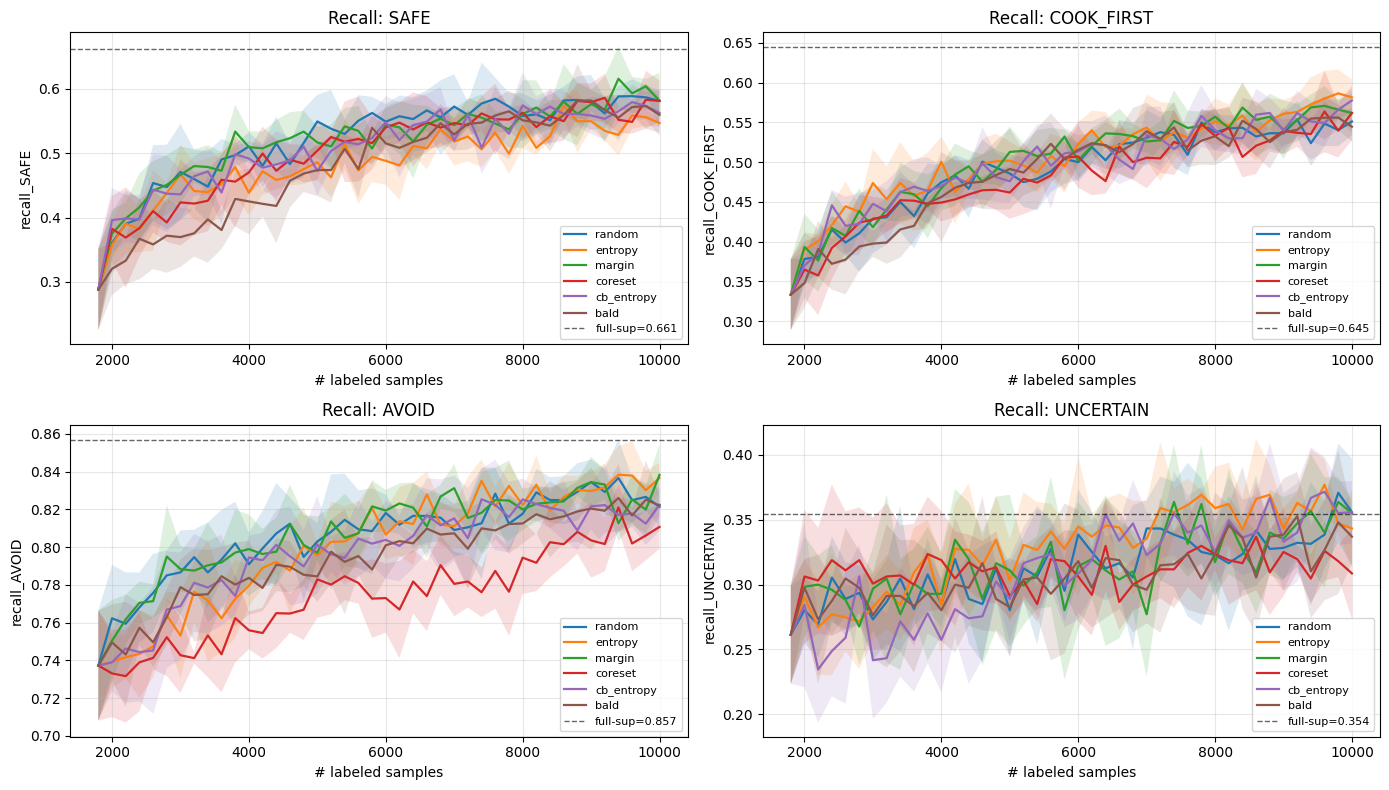

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, b in zip(axes.flat, BUCKET_ORDER):
    metric = f'recall_{b}'
    ceiling = full_bucket_recalls[bucket_to_idx[b]]
    plot_curve(results, metric, ax, f'Recall: {b}', ceiling=ceiling)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'v4_per_bucket_recall.png', dpi=120, bbox_inches='tight')
plt.show()

## Step 11 — Final Results Summary

In [21]:
final_round = results[results['n_labels'] == MAX_LABELS]

summary_cols = ['species_acc', 'species_f1', 'bucket_acc', 'bucket_f1'] + \
               [f'recall_{b}' for b in BUCKET_ORDER]

mean_only = final_round.groupby('strategy')[summary_cols].mean().round(3)
# Shorten names for readability
mean_only.columns = [c.replace('recall_', '').replace('_acc', '_a').replace('_f1', '_f') 
                     for c in mean_only.columns]
print(f"Final at {MAX_LABELS} labels (mean over {N_SEEDS} seeds):\n")
print(mean_only.to_string())

# Separate rankings
print(f"\n=== Ranked by SPECIES accuracy ===")
print(final_round.groupby('strategy')['species_acc'].mean().round(3).sort_values(ascending=False).to_string())

print(f"\n=== Ranked by BUCKET accuracy ===")
print(final_round.groupby('strategy')['bucket_acc'].mean().round(3).sort_values(ascending=False).to_string())

print(f"\n=== Ranked by BUCKET macro F1 ===")
print(final_round.groupby('strategy')['bucket_f1'].mean().round(3).sort_values(ascending=False).to_string())

print(f"\n=== Ranked by UNCERTAIN recall ===")
print(final_round.groupby('strategy')['recall_UNCERTAIN'].mean().round(3).sort_values(ascending=False).to_string())

final_round.groupby('strategy')[summary_cols].agg(['mean', 'std']).round(3).to_csv(
    RESULTS_DIR / 'v4_final_summary.csv'
)

Final at 10000 labels (mean over 5 seeds):

            species_a  species_f  bucket_a  bucket_f   SAFE  COOK_FIRST  AVOID  UNCERTAIN
strategy                                                                                 
bald            0.374      0.243     0.690     0.566  0.559       0.545  0.822      0.337
cb_entropy      0.363      0.246     0.699     0.584  0.562       0.577  0.822      0.356
coreset         0.352      0.231     0.689     0.567  0.581       0.562  0.811      0.309
entropy         0.357      0.235     0.705     0.584  0.547       0.581  0.837      0.343
margin          0.374      0.240     0.708     0.591  0.581       0.562  0.838      0.355
random          0.375      0.240     0.696     0.578  0.581       0.551  0.821      0.356

=== Ranked by SPECIES accuracy ===
strategy
random        0.375
bald          0.374
margin        0.374
cb_entropy    0.363
entropy       0.357
coreset       0.352

=== Ranked by BUCKET accuracy ===
strategy
margin        0.708
entropy

## Step 12 — Label Efficiency

How many labels does each strategy need to reach X% of full-sup bucket accuracy?

In [22]:
def labels_to_reach(results, strategy, seed, metric, target):
    sub = results[(results['strategy']==strategy) & (results['seed']==seed)]
    sub = sub.sort_values('n_labels')
    hit = sub[sub[metric] >= target]
    return int(hit.iloc[0]['n_labels']) if len(hit) > 0 else np.nan

# Targets: 80% and 95% of full-sup bucket accuracy
targets = [
    ('bucket_acc', 0.80 * full_bucket_acc, '80% of full-sup bucket_acc'),
    ('bucket_acc', 0.95 * full_bucket_acc, '95% of full-sup bucket_acc'),
]

rows = []
for metric, threshold, label in targets:
    row = {'target': label, 'threshold': round(threshold, 3)}
    for strategy in STRATEGIES:
        ls = [labels_to_reach(results, strategy, s, metric, threshold) for s in SEEDS]
        row[strategy] = np.nanmean(ls) if not all(np.isnan(ls)) else 'N/A'
    rows.append(row)

eff_df = pd.DataFrame(rows)
print("Labels needed to reach target (mean across seeds):")
print(eff_df.to_string(index=False))
eff_df.to_csv(RESULTS_DIR / 'v4_label_efficiency.csv', index=False)

Labels needed to reach target (mean across seeds):
                    target  threshold  random  entropy  margin coreset cb_entropy    bald
80% of full-sup bucket_acc      0.598  2400.0   2680.0  2280.0  2920.0     2640.0  2920.0
95% of full-sup bucket_acc      0.710     N/A   9600.0  9900.0     N/A        N/A     N/A


In [23]:
# ========== SOFT aggregation ranking ==========
print("=" * 60)
print("SOFT aggregation results (Σ species probs per bucket)")
print("=" * 60)

# Final round summary for soft
soft_cols = ['bucket_acc_soft', 'bucket_f1_soft']
soft_summary = final_round.groupby('strategy')[soft_cols].mean().round(3)
soft_summary.columns = ['bucket_acc_soft', 'bucket_f1_soft']
print(f"\nFinal soft metrics at {MAX_LABELS} labels:\n")
print(soft_summary.to_string())

# Ranked by soft bucket accuracy
print(f"\n=== Ranked by SOFT bucket accuracy ===")
print(final_round.groupby('strategy')['bucket_acc_soft'].mean().round(3).sort_values(ascending=False).to_string())

print(f"\n=== Ranked by SOFT bucket macro F1 ===")
print(final_round.groupby('strategy')['bucket_f1_soft'].mean().round(3).sort_values(ascending=False).to_string())

# Compare hard vs soft side-by-side
print(f"\n=== HARD vs SOFT comparison (mean over {N_SEEDS} seeds) ===")
compare = pd.DataFrame({
    'bucket_acc_HARD':  final_round.groupby('strategy')['bucket_acc'].mean().round(3),
    'bucket_acc_SOFT':  final_round.groupby('strategy')['bucket_acc_soft'].mean().round(3),
    'bucket_f1_HARD':   final_round.groupby('strategy')['bucket_f1'].mean().round(3),
    'bucket_f1_SOFT':   final_round.groupby('strategy')['bucket_f1_soft'].mean().round(3),
})
compare['acc_delta'] = (compare['bucket_acc_SOFT'] - compare['bucket_acc_HARD']).round(3)
compare['f1_delta']  = (compare['bucket_f1_SOFT'] - compare['bucket_f1_HARD']).round(3)
print(compare.sort_values('bucket_acc_SOFT', ascending=False).to_string())

SOFT aggregation results (Σ species probs per bucket)

Final soft metrics at 10000 labels:

            bucket_acc_soft  bucket_f1_soft
strategy                                   
bald                  0.715           0.576
cb_entropy            0.718           0.583
coreset               0.713           0.571
entropy               0.721           0.585
margin                0.721           0.584
random                0.721           0.587

=== Ranked by SOFT bucket accuracy ===
strategy
entropy       0.721
margin        0.721
random        0.721
cb_entropy    0.718
bald          0.715
coreset       0.713

=== Ranked by SOFT bucket macro F1 ===
strategy
random        0.587
entropy       0.585
margin        0.584
cb_entropy    0.583
bald          0.576
coreset       0.571

=== HARD vs SOFT comparison (mean over 5 seeds) ===
            bucket_acc_HARD  bucket_acc_SOFT  bucket_f1_HARD  bucket_f1_SOFT  acc_delta  f1_delta
strategy                                                           

## Step 13 — Key Findings & Discussion

Questions to answer from the figures and tables:

1. **Species supervision validation**: Does bucket accuracy under species training (10k labels) exceed the V3 direct bucket training (3k labels, ~65%)? If so, richer supervision wins.

2. **Gap to full-sup**: What fraction of full-sup bucket accuracy is recovered at 31% of labels? A strong result: 95% recovery with 31% labels = 3× label efficiency.

3. **Strategy ranking shifts**: Under 179-class species training, does BALD benefit more than under 4-class training (where its epistemic signal was coarse)?

4. **Species vs bucket rankings differ?**: Strategies that excel on species-level fine-grained accuracy may not excel on bucket-level aggregation. This is diagnostic of **what kind of mistake each strategy makes**:
   - Strategy with high species_acc but moderate bucket_acc → makes many cross-bucket errors
   - Strategy with moderate species_acc but high bucket_acc → mistakes stay within the same bucket (same-genus confusion)

5. **AL vs full-sup Pareto**: Can any strategy exceed full-sup on specific minority bucket recalls? Under V3 this happened for UNCERTAIN recall — does it persist?

## Comparison to V3 (direct bucket training)

| | V3 (bucket train, 3k labels) | V4 (species train, 10k labels) |
|---|---|---|
| Best bucket acc | 0.654 (margin) | **[from your run]** |
| Best UNCERTAIN recall | 0.518 (coreset) | **[from your run]** |
| Best bucket F1 | 0.517 (margin) | **[from your run]** |

Compare these numbers to quantify the value of fine-grained supervision.
